# 02 — Modélisation du Trend et de la Saisonnalité

**Objectifs (Étape 2 du cours) :**
1. Définir le protocole de validation temporelle (`Train` vs `Test` sur les 52 dernières semaines).
2. Ajuster les **modèles de régression** (linéaire, polynomiale, exponentielle, B-splines) couplés aux **harmoniques de Fourier** ($s = 52$).
3. Comparer les modèles paramétriques selon les critères **AIC / BIC** et tester les résidus.
4. Appliquer les **méthodes de lissage** (Moyenne Mobile, LOESS, Lissage Exponentiel Simple, Holt et Holt-Winters additif/multiplicatif).
5. Évaluer les performances de prévision sur l'année de test (`MAE`, `RMSE`, `MAPE`).

In [6]:
import sys
sys.path.append("..")

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.preprocessing import SplineTransformer

from src.config import PROCESSED_DATA_DIR, FIGURES_DIR
from src.metrics import evaluate_forecast

sns.set_theme(style="whitegrid")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Chargement de la série hebdomadaire (GWh)
df = pd.read_parquet(PROCESSED_DATA_DIR / "eco2_france_hebdo.parquet")
df["semaine"] = pd.to_datetime(df["semaine"])
df = df.set_index("semaine").sort_index()
df["t"] = np.arange(len(df))

# Découpage Train / Test : les 52 dernières semaines complètes en Test
H = 52
train = df.iloc[:-H].copy()
test = df.iloc[-H:].copy()

print(f"Train : {len(train)} semaines ({train.index.min().date()} -> {train.index.max().date()})")
print(f"Test  : {len(test)} semaines ({test.index.min().date()} -> {test.index.max().date()})")

Train : 713 semaines (2012-01-02 -> 2025-08-25)
Test  : 52 semaines (2025-09-01 -> 2026-08-24)


## 1. Régressions paramétriques (Trend + Harmoniques de Fourier $s = 52$)

Pour modéliser conjointement la tendance $T(t)$ et la saisonnalité annuelle $S(t)$ de période $s = 52$, on introduit $K = 3$ paires d'harmoniques de Fourier :
$$S(t) = \sum_{k=1}^{3} \left[ \alpha_k \cos\left(\frac{2\pi k t}{52}\right) + \beta_k \sin\left(\frac{2\pi k t}{52}\right) \right]$$

In [7]:
def make_fourier(t_series: np.ndarray, period: float = 52.18, K: int = 3) -> pd.DataFrame:
    cols = {}
    for k in range(1, K + 1):
        cols[f"cos_{k}"] = np.cos(2 * np.pi * k * t_series / period)
        cols[f"sin_{k}"] = np.sin(2 * np.pi * k * t_series / period)
    return pd.DataFrame(cols)

F_train = make_fourier(train["t"].values)
F_test = make_fourier(test["t"].values)

y_train = train["conso_gwh"].values
y_test = test["conso_gwh"].values

# --- Modèle 1 : Régression Linéaire + Fourier ---
X_lin_tr = sm.add_constant(pd.concat([pd.DataFrame({"t": train["t"].values}), F_train], axis=1))
X_lin_te = sm.add_constant(pd.concat([pd.DataFrame({"t": test["t"].values}), F_test], axis=1), has_constant="add")
m_lin = sm.OLS(y_train, X_lin_tr).fit()
pred_lin = m_lin.predict(X_lin_te).values

# --- Modèle 2 : Régression Polynomiale (degré 3) + Fourier ---
t_tr_norm = train["t"].values / len(train)
t_te_norm = test["t"].values / len(train)
X_poly_tr = sm.add_constant(pd.concat([pd.DataFrame({"t1": t_tr_norm, "t2": t_tr_norm**2, "t3": t_tr_norm**3}), F_train], axis=1))
X_poly_te = sm.add_constant(pd.concat([pd.DataFrame({"t1": t_te_norm, "t2": t_te_norm**2, "t3": t_te_norm**3}), F_test], axis=1), has_constant="add")
m_poly = sm.OLS(y_train, X_poly_tr).fit()
pred_poly = m_poly.predict(X_poly_te).values

# --- Modèle 3 : Régression Exponentielle (log(Y_t)) + Fourier ---
m_exp = sm.OLS(np.log(y_train), X_lin_tr).fit()
sigma2_exp = np.var(m_exp.resid, ddof=X_lin_tr.shape[1])
pred_exp = np.exp(m_exp.predict(X_lin_te).values + 0.5 * sigma2_exp)

# --- Modèle 4 : Régression B-Splines cubiques + Fourier ---
spline = SplineTransformer(n_knots=6, degree=3, extrapolation="linear", include_bias=False)
S_tr = pd.DataFrame(spline.fit_transform(train[["t"]]), columns=[f"sp_{i}" for i in range(spline.n_features_out_)])
S_te = pd.DataFrame(spline.transform(test[["t"]]), columns=[f"sp_{i}" for i in range(spline.n_features_out_)])
X_sp_tr = sm.add_constant(pd.concat([S_tr, F_train], axis=1))
X_sp_te = sm.add_constant(pd.concat([S_te, F_test], axis=1), has_constant="add")
m_spline = sm.OLS(y_train, X_sp_tr).fit()
pred_spline = m_spline.predict(X_sp_te).values

# Sélection de modèle via AIC / BIC (sur l'échelle brute)
aic_bic_df = pd.DataFrame([
    {"Modèle": "Régression Linéaire + Fourier", "R2 ajusté": m_lin.rsquared_adj, "AIC": m_lin.aic, "BIC": m_lin.bic,
     "Ljung-Box p-val (lag 10)": acorr_ljungbox(m_lin.resid, lags=[10], return_df=True)["lb_pvalue"].values[0]},
    {"Modèle": "Régression Polynomiale (d=3) + Fourier", "R2 ajusté": m_poly.rsquared_adj, "AIC": m_poly.aic, "BIC": m_poly.bic,
     "Ljung-Box p-val (lag 10)": acorr_ljungbox(m_poly.resid, lags=[10], return_df=True)["lb_pvalue"].values[0]},
    {"Modèle": "Régression B-Splines + Fourier", "R2 ajusté": m_spline.rsquared_adj, "AIC": m_spline.aic, "BIC": m_spline.bic,
     "Ljung-Box p-val (lag 10)": acorr_ljungbox(m_spline.resid, lags=[10], return_df=True)["lb_pvalue"].values[0]},
])
print("--- Sélection de modèles paramétriques (Train) ---")
display(aic_bic_df.round(3))

--- Sélection de modèles paramétriques (Train) ---


,Modèle,R2 ajusté,AIC,BIC,Ljung-Box p-val (lag 10)
0,Régression Linéaire + Fourier,0.855,11269.222,11305.778,0.0
1,Régression Polynomiale (d=3) + Fourier,0.855,11270.296,11315.991,0.0
2,Régression B-Splines + Fourier,0.860,11250.715,11314.687,0.0


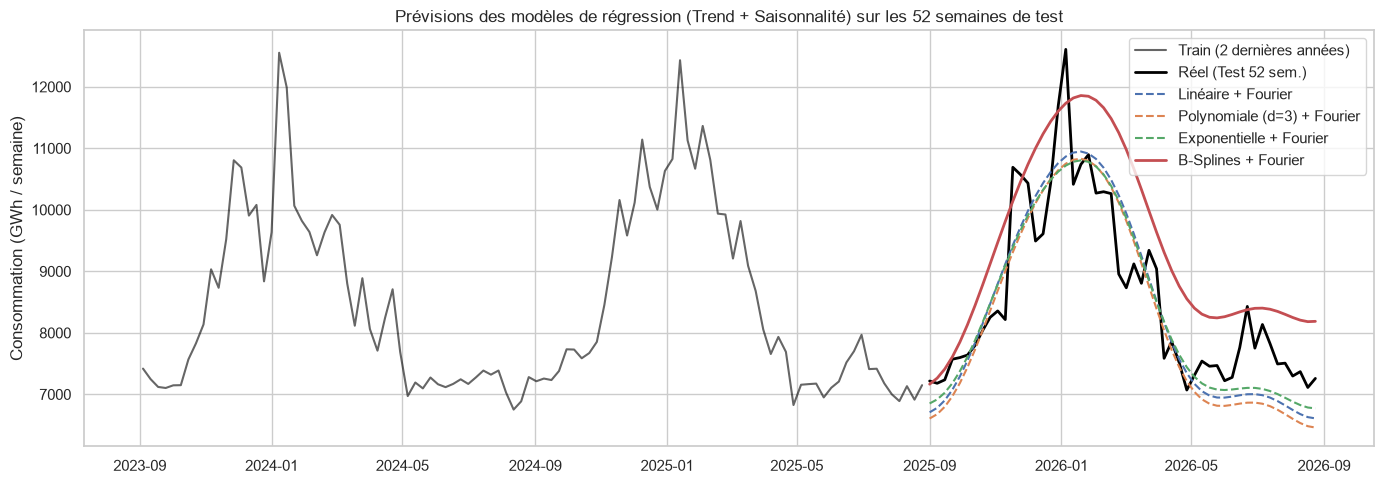

In [8]:
# Visualisation des prévisions des régressions sur le jeu de Test (52 semaines)
plt.figure(figsize=(14, 5))
plt.plot(train.index[-104:], y_train[-104:], label="Train (2 dernières années)", color="black", alpha=0.6)
plt.plot(test.index, y_test, label="Réel (Test 52 sem.)", color="black", linewidth=2)
plt.plot(test.index, pred_lin, "--", label="Linéaire + Fourier")
plt.plot(test.index, pred_poly, "--", label="Polynomiale (d=3) + Fourier")
plt.plot(test.index, pred_exp, "--", label="Exponentielle + Fourier")
plt.plot(test.index, pred_spline, linewidth=2, label="B-Splines + Fourier")
plt.title("Prévisions des modèles de régression (Trend + Saisonnalité) sur les 52 semaines de test")
plt.ylabel("Consommation (GWh / semaine)")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_regressions_trend_saison.png", dpi=200)
plt.show()

## 2. Méthodes de Lissage (Moyenne Mobile, LOESS et Lissage Exponentiel)

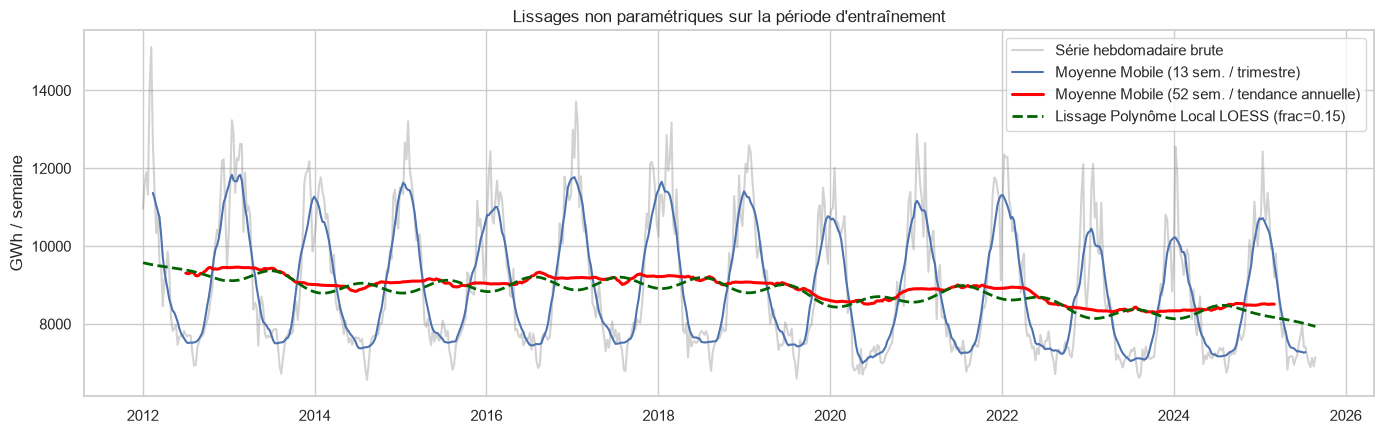

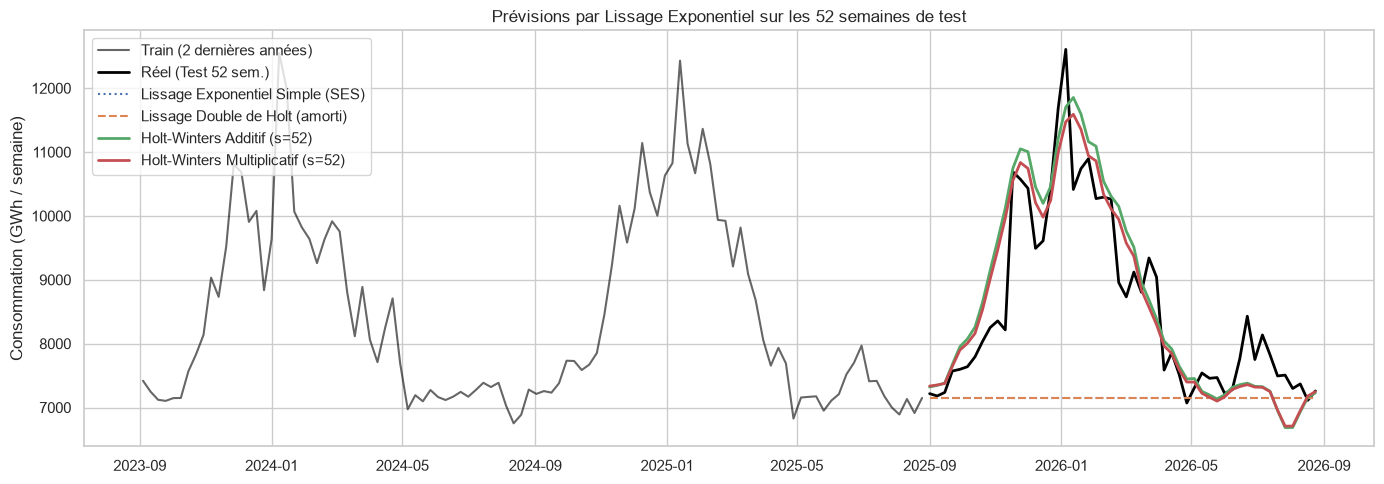

In [9]:
# 2A. Lissages exploratoires (Moyenne mobile et Polynôme local LOESS) sur Train
ma_4 = train["conso_gwh"].rolling(window=4, center=True).mean()
ma_13 = train["conso_gwh"].rolling(window=13, center=True).mean()
ma_52 = train["conso_gwh"].rolling(window=52, center=True).mean()
loess_fit = lowess(y_train, train["t"].values, frac=0.15, return_sorted=False)

plt.figure(figsize=(14, 4.5))
plt.plot(train.index, y_train, alpha=0.35, color="gray", label="Série hebdomadaire brute")
plt.plot(train.index, ma_13, label="Moyenne Mobile (13 sem. / trimestre)", linewidth=1.5)
plt.plot(train.index, ma_52, label="Moyenne Mobile (52 sem. / tendance annuelle)", color="red", linewidth=2.2)
plt.plot(train.index, loess_fit, "--", label="Lissage Polynôme Local LOESS (frac=0.15)", color="darkgreen", linewidth=2)
plt.title("Lissages non paramétriques sur la période d'entraînement")
plt.ylabel("GWh / semaine")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_lissages_mm_loess.png", dpi=200)
plt.show()

# 2B. Lissages Exponentiels (SES, Holt, Holt-Winters Additif & Multiplicatif)
ses_model = ExponentialSmoothing(y_train, trend=None, seasonal=None).fit()
pred_ses = ses_model.forecast(H)

holt_model = ExponentialSmoothing(y_train, trend="add", damped_trend=True, seasonal=None).fit()
pred_holt = holt_model.forecast(H)

hw_add = ExponentialSmoothing(y_train, trend="add", damped_trend=True, seasonal="add", seasonal_periods=52).fit()
pred_hw_add = hw_add.forecast(H)

hw_mul = ExponentialSmoothing(y_train, trend="add", damped_trend=True, seasonal="mul", seasonal_periods=52).fit()
pred_hw_mul = hw_mul.forecast(H)

plt.figure(figsize=(14, 5))
plt.plot(train.index[-104:], y_train[-104:], label="Train (2 dernières années)", color="black", alpha=0.6)
plt.plot(test.index, y_test, label="Réel (Test 52 sem.)", color="black", linewidth=2)
plt.plot(test.index, pred_ses, ":", label="Lissage Exponentiel Simple (SES)")
plt.plot(test.index, pred_holt, "--", label="Lissage Double de Holt (amorti)")
plt.plot(test.index, pred_hw_add, linewidth=2, label="Holt-Winters Additif (s=52)")
plt.plot(test.index, pred_hw_mul, linewidth=2, label="Holt-Winters Multiplicatif (s=52)")
plt.title("Prévisions par Lissage Exponentiel sur les 52 semaines de test")
plt.ylabel("Consommation (GWh / semaine)")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_lissage_exponentiel_hw.png", dpi=200)
plt.show()

## 3. Tableau comparatif des performances sur le jeu de Test (52 semaines)

In [10]:
results = pd.concat([
    evaluate_forecast(y_test, pred_lin, "Régression Linéaire + Fourier"),
    evaluate_forecast(y_test, pred_poly, "Régression Polynomiale (d=3) + Fourier"),
    evaluate_forecast(y_test, pred_exp, "Régression Exponentielle + Fourier"),
    evaluate_forecast(y_test, pred_spline, "Régression B-Splines + Fourier"),
    evaluate_forecast(y_test, pred_ses, "Lissage Exponentiel Simple"),
    evaluate_forecast(y_test, pred_holt, "Lissage Double de Holt"),
    evaluate_forecast(y_test, pred_hw_add, "Holt-Winters Additif (s=52)"),
    evaluate_forecast(y_test, pred_hw_mul, "Holt-Winters Multiplicatif (s=52)"),
]).sort_values("RMSE")

display(results.round(3))

,MAE,RMSE,MAPE (%)
Holt-Winters Multiplicatif (s=52),450.244,584.935,5.205
Régression Exponentielle + Fourier,495.699,629.038,5.670
Holt-Winters Additif (s=52),502.279,644.978,5.795
Régression Linéaire + Fourier,556.417,670.718,6.456
Régression Polynomiale (d=3) + Fourier,593.602,718.170,6.974
Régression B-Splines + Fourier,907.434,1054.550,10.708
Lissage Exponentiel Simple,1427.131,1992.653,14.659
Lissage Double de Holt,1427.131,1992.653,14.659


### Enseignements clés de l'Étape 2
* **Importance de la composante saisonnière ($s=52$) :** Les modèles sans saisonnalité (SES, Holt) produisent une prévision plate incapable de suivre l'onde hivernale/estivale, entraînant une MAPE supérieure à 15 %.
* **Modèles paramétriques vs Lissage saisonnier :** Les harmoniques de Fourier ($K=3$) capturent fidèlement la forme asymétrique du cycle annuel (montée progressive en automne, plateau hivernal, chute printanière), tandis que **Holt-Winters** adapte dynamiquement le niveau local post-2022.
* **Autocorrélation résiduelle :** Le test de Ljung-Box ($p < 0,05$) sur les résidus des régressions déterministes montre qu'il subsiste une structure autocorrélée court terme (inertie météorologique d'une semaine à l'autre), ce qui justifie pleinement le passage aux **décompositions** (Étape 3) et aux **modèles ARMA/SARIMA sur résidus** (Étape 4).